<a href="https://colab.research.google.com/github/francji1/01NAEX/blob/main/code/01NAEX_Ex07.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01NAEX - Exercise 07: Center points, blocking and confounding in the $2^k$ design

Data and exercises come from D. C. Montgomery: *Design and Analysis of Experiments*, 8th edition, Chapter 6
(Sections 6.7 and 6.8) and Chapter 7. Problem numbers follow the 8th edition.

## Learning goals

* Explain in which sense the $2^k$ designs are D-, G- and I-optimal and compute the prediction variance of a design.
* Add center points to a $2^k$ design: estimate the pure error, test for pure quadratic curvature (by hand, with an indicator
  variable and as lack of fit) and understand why only $\sum_j \beta_{jj}$ is estimable.
* Analyze a replicated $2^k$ design run in blocks.
* Construct a $2^k$ design in $2^p$ blocks (table of signs, defining contrasts, principal block), find all effects confounded
  with blocks and choose a good confounding scheme.
* Analyze an unreplicated design run in blocks and see what happens if we do not block.
* Analyze a partially confounded design.

## Setup

Run this cell first. Besides the standard imports it defines helper functions used below:

* `effects_2k()` - contrasts, effects, sums of squares and coded coefficients of a $2^k$ design (Exercises 5 and 6).
* `effect_plot()` - normal (or half-normal) probability plot of the effects with a reference line through the small effects.
* `lenth()` - Lenth's pseudo standard error $PSE$, margin of error $ME$ and simultaneous margin of error $SME$.
* `multiply()` - product of two effects modulo 2, e.g. `multiply("ADE", "BCE") == "ABCD"`.
* `confounded_effects()` - all effects confounded with blocks for given independent generators.
* `design_in_blocks()` - a $2^k$ design in $2^p$ blocks built with the defining contrasts $L_i \pmod 2$.

In [1]:
import itertools
from functools import reduce

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm

URL = "https://raw.githubusercontent.com/francji1/01NAEX/main/data/"


def effects_2k(data, response, factors):
    """Contrasts, effects, sums of squares and coded coefficients of a balanced 2^k design.

    `factors` are columns coded -1/+1 (main effects in this order: A, B, C, ...). Rows are in standard order
    (A, B, AB, C, AC, BC, ABC, ...) and are named as in statsmodels formulas ("A:B").
    """
    k = len(factors)
    n = len(data) // 2**k
    rows = []
    for i in range(1, 2**k):
        members = [factors[j] for j in range(k) if i >> j & 1]
        sign = data[members].prod(axis=1)
        contrast = (sign * data[response]).sum()
        rows.append({"term": ":".join(members), "contrast": contrast,
                     "effect": contrast / (n * 2**(k - 1)), "SS": contrast**2 / (n * 2**k)})
    table = pd.DataFrame(rows).set_index("term")
    table["coef"] = table["effect"] / 2
    return table


def effect_plot(effects, half=False, n_label=5, ax=None, title=None):
    """Normal (Daniel) or half-normal probability plot of the effects (a pd.Series indexed by the effect names).

    The reference line is fitted to the smaller half of the effects (through the origin for the half-normal plot).
    The n_label largest effects (in absolute value) are labelled.
    """
    e = (effects.abs() if half else effects).sort_values()
    m = len(e)
    p = (np.arange(1, m + 1) - 0.5) / m
    q = stats.halfnorm.ppf(p) if half else stats.norm.ppf(p)
    x = e.to_numpy(dtype=float)
    small = np.argsort(np.abs(x))[: m // 2 + 1]
    if half:
        b, a = (x[small] @ q[small]) / (q[small] @ q[small]), 0.0
        qq = np.linspace(0, q.max(), 50)
    else:
        b, a = np.polyfit(q[small], x[small], 1)
        qq = np.linspace(q.min(), q.max(), 50)
    if ax is None:
        ax = plt.subplots(figsize=(5, 4))[1]
    ax.scatter(x, q, color="k", s=20)
    ax.plot(a + b * qq, qq, color="tab:red", lw=1)
    largest = effects.abs().sort_values().index[-n_label:] if n_label else []
    for name, xi, qi in zip(e.index, x, q):
        if name in largest:
            ax.annotate(name, (xi, qi), xytext=(4, -3), textcoords="offset points")
    ax.set_xlabel("|effect|" if half else "effect")
    ax.set_ylabel("half-normal quantile" if half else "normal quantile")
    ax.set_title(title or ("Half-normal plot of effects" if half else "Normal probability plot of effects"))
    return ax


def lenth(effects, alpha=0.05):
    """Lenth's method: s0, pseudo standard error, margin of error and simultaneous margin of error."""
    c = np.abs(np.asarray(effects, dtype=float))
    m = len(c)
    s0 = 1.5 * np.median(c)
    pse = 1.5 * np.median(c[c < 2.5 * s0])
    d = m / 3
    me = stats.t.ppf(1 - alpha / 2, d) * pse
    gamma = (1 + (1 - alpha) ** (1 / m)) / 2
    sme = stats.t.ppf(gamma, d) * pse
    return {"s0": s0, "PSE": pse, "ME": me, "SME": sme}


def multiply(*effects):
    """Product of effects modulo 2 (squared letters cancel): multiply("ADE", "BCE") -> "ABCD"."""
    letters = reduce(lambda s, e: s ^ set(e), effects, set())
    return "".join(sorted(letters)) or "I"


def confounded_effects(generators):
    """All 2^p - 1 effects confounded with blocks: the generators and all their generalized interactions."""
    out = []
    for r in range(1, len(generators) + 1):
        for comb in itertools.combinations(generators, r):
            out.append(multiply(*comb))
    return out


def design_in_blocks(k, generators):
    """2^k design (standard order, columns coded -1/+1) in 2^p blocks given by the defining contrasts of the generators.

    L_i = sum of x_j (x_j = 0/1 levels) over the letters of generator i, modulo 2. Runs with the same (L_1, ..., L_p)
    form one block; the principal block (the one containing (1)) is block 1.
    """
    letters = "ABCDEFGHIJ"[:k]
    runs = []
    for levels in itertools.product([0, 1], repeat=k):
        x = dict(zip(letters, levels[::-1]))          # A changes fastest = standard order
        L = tuple(sum(x[c] for c in g) % 2 for g in generators)
        label = "".join(c.lower() for c in letters if x[c]) or "(1)"
        runs.append({**{c: 2 * x[c] - 1 for c in letters}, "label": label, "L": L})
    d = pd.DataFrame(runs)
    order = sorted(d["L"].unique())                     # (0, ..., 0) first = principal block
    d["Block"] = d["L"].map({L: i + 1 for i, L in enumerate(order)})
    return d

## 1. Lecture example: $2^k$ designs are optimal designs

For the $2^2$ design and the model $y = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \beta_{12} x_1 x_2 + \varepsilon$ the model
matrix $\mathbf X$ has orthogonal columns, $\mathbf X'\mathbf X = 4\mathbf I$ and $V(\hat\beta_j) = \sigma^2/4$.
We compare it with a design that has the same structure but the factor levels only at $\pm 0.5$ (factors spaced too closely).

In [2]:
def model_matrix(points):
    x1, x2 = np.asarray(points, dtype=float).T
    return np.column_stack([np.ones_like(x1), x1, x2, x1 * x2])

corners = [(-1, -1), (1, -1), (-1, 1), (1, 1)]
designs = {
    "2^2": corners,
    "2^2 at +-0.5": [(0.5 * a, 0.5 * b) for a, b in corners],
    "2^2 + 1 center": corners + [(0, 0)],
    "2^2 + 4 centers": corners + [(0, 0)] * 4,
}
rows = []
for name, pts in designs.items():
    X = model_matrix(pts)
    M = X.T @ X
    N, p = X.shape
    rows.append({"design": name, "N": N, "det(X'X)": np.linalg.det(M),
                 "D-efficiency det^(1/p)/N": np.linalg.det(M) ** (1 / p) / N,
                 "V(b_1)/sigma^2": np.linalg.inv(M)[1, 1]})
pd.DataFrame(rows).round(4)

,design,N,det(X'X),D-efficiency det^(1/p)/N,V(b_1)/sigma^2
0,2^2,4,256.0,1.0000,0.25
1,2^2 at +-0.5,4,1.0,0.2500,1.00
2,2^2 + 1 center,5,320.0,0.8459,0.25
3,2^2 + 4 centers,8,512.0,0.5946,0.25


The $2^2$ design maximizes $\det(\mathbf X'\mathbf X)$ among four-run designs in the square $[-1, 1]^2$ (D-optimality).
Spacing the levels at $\pm 0.5$ makes $V(\hat\beta_1)$ four times larger. Center points do not change the variance of
$\hat\beta_1$, $\hat\beta_2$, $\hat\beta_{12}$; per run they lower the D-efficiency, but they give an estimate of pure error
and a test for curvature.

### Prediction variance, G- and I-optimality

$V[\hat y(\mathbf x)] = \sigma^2 \mathbf f(\mathbf x)'(\mathbf X'\mathbf X)^{-1}\mathbf f(\mathbf x)$, where
$\mathbf f(\mathbf x) = (1, x_1, x_2, x_1x_2)'$. For the $2^2$ design it equals
$\frac{\sigma^2}{4}(1 + x_1^2 + x_2^2 + x_1^2x_2^2)$.

In [3]:
def upv(points, x1, x2):
    """Unscaled prediction variance V[y_hat(x)] / sigma^2 of the first-order model with interaction."""
    Minv = np.linalg.inv(model_matrix(points).T @ model_matrix(points))
    F = np.stack([np.ones_like(x1), x1, x2, x1 * x2], axis=-1)
    return np.einsum("...i,ij,...j->...", F, Minv, F)

g = np.linspace(-1, 1, 401)
x1, x2 = np.meshgrid(g, g)
for name in ["2^2", "2^2 + 1 center"]:
    v = upv(designs[name], x1, x2)
    print(f"{name:16s} max = {v.max():.4f} (G),  average = {v.mean():.4f} (I),  center = {upv(designs[name], 0., 0.):.4f}")
print("p/N for the 2^2 design:", 4 / 4, "   4/9 =", round(4 / 9, 4))

2^2              max = 1.0000 (G),  average = 0.4456 (I),  center = 0.2500
2^2 + 1 center   max = 0.9500 (G),  average = 0.3956 (I),  center = 0.2000
p/N for the 2^2 design: 1.0    4/9 = 0.4444


The maximum prediction variance of the $2^2$ design is $\sigma^2 = p\sigma^2/N$, the smallest possible value (G-optimal),
and the average over the square is $4\sigma^2/9$ (I-optimal; the grid average is a numerical approximation of the
integral). The fraction of design space (FDS) plot shows how the prediction variance is distributed over the region.

2^2: prediction variance <= 0.420 sigma^2 on 50 % of the region
2^2 + 1 center: prediction variance <= 0.370 sigma^2 on 50 % of the region


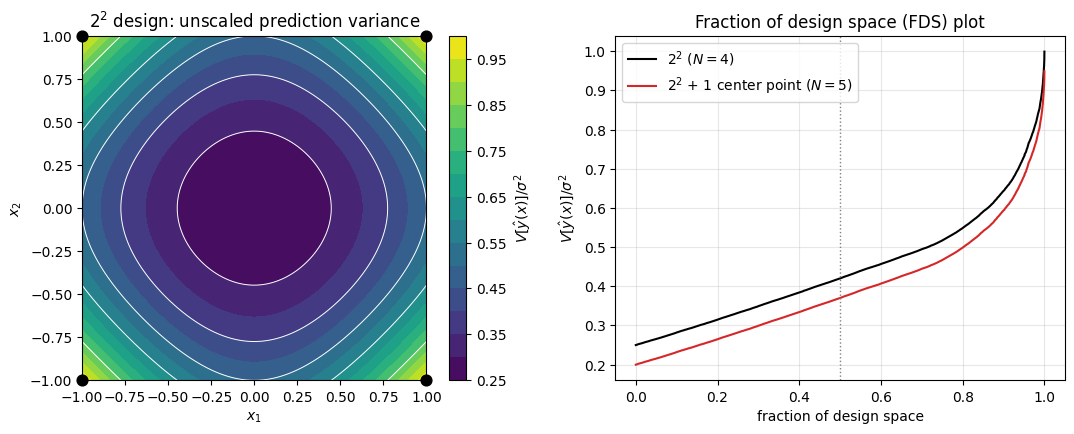

In [4]:
# Figure of Lecture 7: unscaled prediction variance (left) and the fraction of design space plot (right)
rng = np.random.default_rng(1)
u = rng.uniform(-1, 1, size=(20000, 2))          # uniform points in the design region
frac = np.linspace(0, 1, len(u))
fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
v22 = upv(designs["2^2"], x1, x2)
cs = ax[0].contourf(x1, x2, v22, levels=np.arange(0.25, 1.01, 0.05), cmap="viridis")
ax[0].contour(x1, x2, v22, levels=[0.3, 0.4, 0.5, 0.6, 0.8], colors="w", linewidths=0.7)
ax[0].scatter(*np.array(corners).T, s=60, color="k", clip_on=False, zorder=3)
fig.colorbar(cs, ax=ax[0], label=r"$V[\hat y(x)]/\sigma^2$")
ax[0].set(xlabel="$x_1$", ylabel="$x_2$", aspect="equal", title=r"$2^2$ design: unscaled prediction variance")
for name, lab, col in [("2^2", r"$2^2$ ($N=4$)", "k"), ("2^2 + 1 center", r"$2^2$ + 1 center point ($N=5$)", "tab:red")]:
    v = np.sort(upv(designs[name], u[:, 0], u[:, 1]))
    ax[1].plot(frac, v, color=col, label=lab)
    print(f"{name}: prediction variance <= {np.median(v):.3f} sigma^2 on 50 % of the region")
ax[1].axvline(0.5, color="grey", ls=":", lw=1)
ax[1].set(xlabel="fraction of design space", ylabel=r"$V[\hat y(x)]/\sigma^2$",
          title="Fraction of design space (FDS) plot")
ax[1].legend(loc="upper left")
ax[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 2. Lecture example: center points in the filtration rate experiment (Example 6.7)

The filtration rate experiment from Exercise 6 (unreplicated $2^4$ design, $A$ temperature, $B$ pressure, $C$ concentration of
formaldehyde, $D$ stirring rate) with **four center points** added: filtration rates 73, 75, 66 and 69 at
$x_1 = x_2 = x_3 = x_4 = 0$. The file contains the 16 factorial runs in standard order followed by the center points.

In [5]:
f = pd.read_csv(URL + "Pilot_Plant_Filtration_Rate_Experiment3.csv", sep=";")
f["cp"] = (f["A"] == 0).astype(int)         # indicator of the center points
f.tail(6)

,A,B,C,D,Rate,cp
14,-1,1,1,1,70,0
15,1,1,1,1,96,0
16,0,0,0,0,73,1
17,0,0,0,0,75,1
18,0,0,0,0,66,1
19,0,0,0,0,69,1


In [6]:
yF = f.loc[f.cp == 0, "Rate"].mean()
yC = f.loc[f.cp == 1, "Rate"].mean()
nF, nC = (f.cp == 0).sum(), (f.cp == 1).sum()
SS_pq = nF * nC * (yF - yC) ** 2 / (nF + nC)          # pure quadratic curvature, 1 df
MS_pe = f.loc[f.cp == 1, "Rate"].var(ddof=1)            # pure error from the center points, nC - 1 df
F0 = SS_pq / MS_pe
t0 = (yF - yC) / np.sqrt(MS_pe * (1 / nF + 1 / nC))
print(f"yF = {yF:.4f}, yC = {yC:.4f}, yF - yC = {yF - yC:.4f}")
print(f"SS_pure quadratic = {SS_pq:.4f}, MS_pure error = {MS_pe:.4f} ({nC - 1} df)")
print(f"F0 = {F0:.4f}, p = {stats.f.sf(F0, 1, nC - 1):.4f}")
print(f"t0 = {t0:.4f}, t0^2 = {t0**2:.4f}, p = {2 * stats.t.sf(abs(t0), nC - 1):.4f}")

yF = 70.0625, yC = 70.7500, yF - yC = -0.6875
SS_pure quadratic = 1.5125, MS_pure error = 16.2500 (3 df)
F0 = 0.0931, p = 0.7802
t0 = -0.3051, t0^2 = 0.0931, p = 0.7802


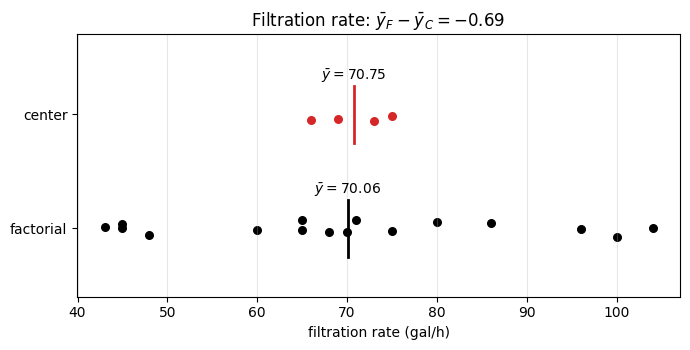

In [7]:
# Figure of Lecture 7: the factorial runs and the center points with their averages
rng = np.random.default_rng(1)
fig, ax = plt.subplots(figsize=(7, 3.6))
for k, (sub, col) in enumerate([(f[f.cp == 0], "k"), (f[f.cp == 1], "tab:red")]):
    ax.scatter(sub.Rate, k + rng.uniform(-0.08, 0.08, len(sub)), color=col, s=30)
    ax.plot([sub.Rate.mean()] * 2, [k - 0.25, k + 0.25], color=col, lw=2)
    ax.annotate(rf"$\bar y = {sub.Rate.mean():.2f}$", (sub.Rate.mean(), k + 0.3), ha="center")
ax.set(yticks=[0, 1], yticklabels=["factorial", "center"], ylim=(-0.6, 1.7), xlabel="filtration rate (gal/h)",
       title=rf"Filtration rate: $\bar y_F - \bar y_C = {yF - yC:.2f}$")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

The averages are very similar, $F_0 = 0.093$ with $1$ and $3$ degrees of freedom ($p = 0.78$): no evidence of pure quadratic
curvature. The $t$-test with $n_C - 1$ degrees of freedom is the same test ($t_0^2 = F_0$).

**Why only the sum $\sum_j \beta_{jj}$?** At the factorial points every $x_j^2 = 1$, at the center $x_j^2 = 0$. All four
columns $x_1^2, \dots, x_4^2$ are identical (and equal to $1 - \texttt{cp}$), so the model matrix of the full second-order
model is rank deficient:

In [8]:
Q = np.column_stack([f[c] ** 2 for c in "ABCD"])
print("identical columns:", all((Q[:, j] == Q[:, 0]).all() for j in range(4)))
print("rank of [x1^2, x2^2, x3^2, x4^2]:", np.linalg.matrix_rank(Q))

identical columns: True
rank of [x1^2, x2^2, x3^2, x4^2]: 1


### Full model with the center-point indicator

Adding the indicator `cp` to the full factorial model separates the curvature sum of squares; the residual is exactly the
pure error from the center points (Montgomery, Table 6.24). Center points do not change any factorial effect estimate.

In [9]:
full = smf.ols("Rate ~ A*B*C*D + cp", data=f).fit()
anova_lm(full).round(4)

,df,sum_sq,mean_sq,F,PR(>F)
A,1.0,1870.5625,1870.5625,115.1115,0.0017
B,1.0,39.0625,39.0625,2.4038,0.2188
A:B,1.0,0.0625,0.0625,0.0038,0.9544
C,1.0,390.0625,390.0625,24.0038,0.0163
A:C,1.0,1314.0625,1314.0625,80.8654,0.0029
B:C,1.0,22.5625,22.5625,1.3885,0.3236
A:B:C,1.0,14.0625,14.0625,0.8654,0.4209
D,1.0,855.5625,855.5625,52.6500,0.0054
A:D,1.0,1105.5625,1105.5625,68.0346,0.0037
B:D,1.0,0.5625,0.5625,0.0346,0.8643


### Reduced model, lack of fit and pure error

Keep $A, C, D, AC, AD$ (Exercise 6) and the indicator. The residual of the reduced model consists of the lack of fit
(the omitted factorial effects) and the pure error (center points). The comparison with the full model is the lack-of-fit test.

In [10]:
red = smf.ols("Rate ~ A*C + A*D + cp", data=f).fit()
display(anova_lm(red).round(4))
anova_lm(red, full).round(4)          # lack of fit (10 df) vs pure error (3 df)

,df,sum_sq,mean_sq,F,PR(>F)
A,1.0,1870.5625,1870.5625,99.7122,0.0000
C,1.0,390.0625,390.0625,20.7927,0.0005
A:C,1.0,1314.0625,1314.0625,70.0474,0.0000
D,1.0,855.5625,855.5625,45.6066,0.0000
A:D,1.0,1105.5625,1105.5625,58.9331,0.0000
cp,1.0,1.5125,1.5125,0.0806,0.7809
Residual,13.0,243.8750,18.7596,NaN,NaN


,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,13.0,243.875,0.0,NaN,NaN,NaN
1,3.0,48.750,10.0,195.125,1.2008,0.4942


In [11]:
# the same reduced model without the indicator: the curvature goes into the residual (14 df)
red0 = smf.ols("Rate ~ A*C + A*D", data=f).fit()
print("SS_E without cp:", round(red0.ssr, 4), " = SS_pq + SS_LOF + SS_PE =",
      round(SS_pq, 4), "+", round(red.ssr - full.ssr, 4), "+", round(full.ssr, 4))

SS_E without cp: 245.3875  = SS_pq + SS_LOF + SS_PE = 1.5125 + 195.125 + 48.75


### Curvature as a regression coefficient

The coefficient of `cp` is $\bar y_C - \bar y_F$, the coefficient of `I(A**2)` is $\bar y_F - \bar y_C$ (any $x_j^2$ gives the
same column). Their $t$-tests use the residual mean square of the reduced model (13 df) instead of the pure error (3 df),
so the $p$-value differs slightly from the $F$-test above.

In [12]:
q = smf.ols("Rate ~ A*C + A*D + I(A**2)", data=f).fit()
pd.DataFrame({"cp model": red.params, "I(A**2) model": q.params.rename({"I(A ** 2)": "cp"})}).round(4)

,cp model,I(A**2) model
Intercept,70.0625,70.7500
A,10.8125,10.8125
C,4.9375,4.9375
A:C,-9.0625,-9.0625
D,7.3125,7.3125
A:D,8.3125,8.3125
cp,0.6875,-0.6875


In [13]:
print("cp:      t =", round(red.tvalues["cp"], 4), " p =", round(red.pvalues["cp"], 4))
print("I(A**2): t =", round(q.tvalues["I(A ** 2)"], 4), " p =", round(q.pvalues["I(A ** 2)"], 4))

cp:      t = 0.2839  p = 0.7809
I(A**2): t = -0.2839  p = 0.7809


If the curvature test were significant, we would augment the design with axial runs and fit the second-order model with a
**central composite design** (Montgomery, Chapter 11).

## 3. Lecture example: blocking a replicated $2^k$ design (Example 7.1)

The chemical process from Exercise 5 ($A$ reactant concentration, $B$ amount of catalyst, $y$ recovery), three replicates of
the $2^2$ design. Only four runs can be made from one batch of raw material, so each replicate is run with a different batch
(block).

In [14]:
chem = pd.DataFrame({
    "A": [-1, 1, -1, 1] * 3,
    "B": [-1, -1, 1, 1] * 3,
    "Block": np.repeat([1, 2, 3], 4),
    "y": [28, 36, 18, 31, 25, 32, 19, 30, 27, 32, 23, 29],
})
chem["Block"] = chem["Block"].astype("category")
print(chem.groupby("Block", observed=True)["y"].sum())
blocked = smf.ols("y ~ Block + A*B", data=chem).fit()
anova_lm(blocked).round(4)

Block
1    113
2    106
3    111
Name: y, dtype: int64


,df,sum_sq,mean_sq,F,PR(>F)
Block,2.0,6.5000,3.2500,0.7852,0.4978
A,1.0,208.3333,208.3333,50.3356,0.0004
B,1.0,75.0000,75.0000,18.1208,0.0053
A:B,1.0,8.3333,8.3333,2.0134,0.2057
Residual,6.0,24.8333,4.1389,NaN,NaN


In [15]:
unblocked = smf.ols("y ~ A*B", data=chem).fit()
print("MS_E with blocks:   ", round(blocked.mse_resid, 4), "on", int(blocked.df_resid), "df")
print("MS_E without blocks:", round(unblocked.mse_resid, 4), "on", int(unblocked.df_resid), "df")

MS_E with blocks:    4.1389 on 6 df
MS_E without blocks: 3.9167 on 8 df


The factorial sums of squares do not change; $SS_{Blocks} = 6.50$ (2 df) is removed from the error. Here the blocks are
small ($MS_{Blocks} = 3.25 < MS_E$) and blocking costs two error degrees of freedom - but we could not know it before the
experiment. The $F$-test for blocks is only an informal comparison (randomization was restricted to within blocks).

## 4. Constructing a $2^k$ design in $2^p$ blocks

### Two blocks: the $2^3$ design with $ABC$ confounded

Method 1 - the table of signs: runs with $ABC = -1$ go to one block, runs with $ABC = +1$ to the other.
Method 2 - the defining contrast $L = x_1 + x_2 + x_3 \pmod 2$ with $x_i \in \{0, 1\}$.

In [16]:
d3 = design_in_blocks(3, ["ABC"])
d3["ABC"] = d3.A * d3.B * d3.C
d3

,A,B,C,label,L,Block,ABC
0,-1,-1,-1,(1),"(0,)",1,-1
1,1,-1,-1,a,"(1,)",2,1
2,-1,1,-1,b,"(1,)",2,1
3,1,1,-1,ab,"(0,)",1,-1
4,-1,-1,1,c,"(1,)",2,1
5,1,-1,1,ac,"(0,)",1,-1
6,-1,1,1,bc,"(0,)",1,-1
7,1,1,1,abc,"(1,)",2,1


In [17]:
for b, grp in d3.groupby("Block"):
    print(f"block {b}:", " ".join(grp.label))
# the main effects and two-factor interactions are balanced within each block
print(d3.groupby("Block")[["A", "B", "C"]].sum())

block 1: (1) ab ac bc
block 2: a b c abc
       A  B  C
Block         
1      0  0  0
2      0  0  0


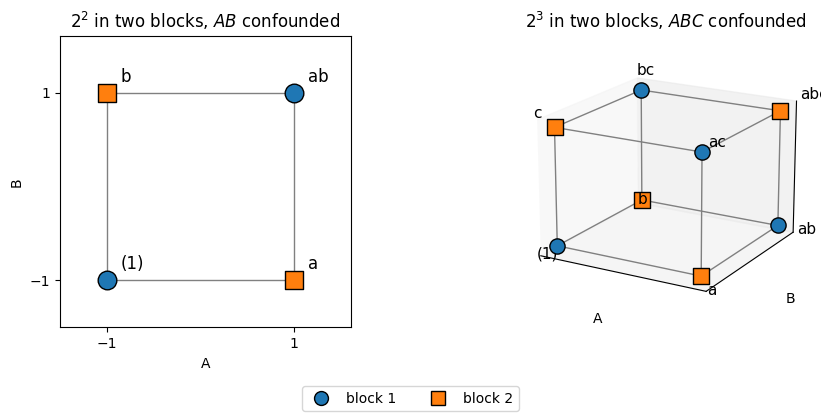

In [18]:
# Figure of Lecture 7: the 2^2 design with AB and the 2^3 design with ABC confounded with blocks
from matplotlib.lines import Line2D
style = {1: dict(marker="o", color="tab:blue"), 2: dict(marker="s", color="tab:orange")}
fig = plt.figure(figsize=(10, 4.2))
a1 = fig.add_subplot(1, 2, 1)
for xa, xb, lab in [(-1, -1, "(1)"), (1, -1, "a"), (-1, 1, "b"), (1, 1, "ab")]:
    a1.scatter(xa, xb, s=180, edgecolor="k", zorder=3, **style[1 if xa * xb > 0 else 2])
    a1.annotate(lab, (xa, xb), xytext=(10, 8), textcoords="offset points", fontsize=12)
a1.plot([-1, 1, 1, -1, -1], [-1, -1, 1, 1, -1], color="grey", lw=1)
a1.set(xlim=(-1.5, 1.6), ylim=(-1.5, 1.6), aspect="equal", xticks=[-1, 1], yticks=[-1, 1], xlabel="A", ylabel="B",
       title=r"$2^2$ in two blocks, $AB$ confounded")
a2 = fig.add_subplot(1, 2, 2, projection="3d")
for e in itertools.product([-1, 1], repeat=3):          # edges of the cube
    for j in range(3):
        if e[j] == -1:
            e2 = list(e)
            e2[j] = 1
            a2.plot(*zip(e, e2), color="grey", lw=1)
for _, r in d3.iterrows():
    a2.scatter(r.A, r.B, r.C, s=120, edgecolor="k", depthshade=False, **style[r.Block])
    a2.text(r.A * 1.18, r.B * 1.18, r.C * 1.18, r.label, fontsize=11)
a2.set(xlabel="A", ylabel="B", zlabel="C", xticks=[], yticks=[], zticks=[],
       title=r"$2^3$ in two blocks, $ABC$ confounded")
a2.view_init(elev=18, azim=-60)
fig.legend(handles=[Line2D([], [], ls="", markeredgecolor="k", ms=10, label=f"block {b}", **style[b]) for b in (1, 2)],
           loc="lower center", ncol=2)
plt.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

**Principal block.** The block with $(1)$ is a group under multiplication modulo 2: the product of any two of its runs is
again in the block. The other block is the principal block multiplied by any run not in it.

In [19]:
def run_product(r1, r2):
    s = set(r1.replace("(1)", "")) ^ set(r2.replace("(1)", ""))
    return "".join(sorted(s)) or "(1)"

principal = list(d3.loc[d3.Block == 1, "label"])
print("principal block:", principal)
print("products:", {f"{r1}*{r2}": run_product(r1, r2) for r1, r2 in itertools.combinations(principal, 2)})
print("b * principal block:", [run_product("b", r) for r in principal])

principal block: ['(1)', 'ab', 'ac', 'bc']
products: {'(1)*ab': 'ab', '(1)*ac': 'ac', '(1)*bc': 'bc', 'ab*ac': 'bc', 'ab*bc': 'ac', 'ac*bc': 'ab'}
b * principal block: ['b', 'a', 'abc', 'c']


### Four blocks: the $2^5$ design with $ADE$ and $BCE$ (Section 7.6)

With two generators the third confounded effect is their generalized interaction $(ADE)(BCE) = ABCDE^2 = ABCD$.

In [20]:
gens = ["ADE", "BCE"]
print("confounded with blocks:", confounded_effects(gens))
d5 = design_in_blocks(5, gens)
for b, grp in d5.groupby("Block"):
    print(f"block {b} (L1, L2) = {grp.L.iloc[0]}:", " ".join(grp.label))

confounded with blocks: ['ADE', 'BCE', 'ABCD']
block 1 (L1, L2) = (0, 0): (1) bc ad abcd abe ace bde cde
block 2 (L1, L2) = (0, 1): b c abd acd ae abce de bcde
block 3 (L1, L2) = (1, 0): a abc d bcd be ce abde acde
block 4 (L1, L2) = (1, 1): ab ac bd cd e bce ade abcde


In [21]:
# check: within each block the sign of every confounded effect is constant
for eff in confounded_effects(gens):
    d5[eff] = d5[list(eff)].prod(axis=1)
d5.groupby("Block")[confounded_effects(gens)].agg(["min", "max"])

ADE     BCE     ABCD    
      min max min max  min max
Block                         
1      -1  -1  -1  -1    1   1
2      -1  -1   1   1   -1  -1
3       1   1  -1  -1   -1  -1
4       1   1   1   1    1   1

A bad choice: confounding $ABCDE$ and $ABD$ looks natural, but it also confounds the two-factor interaction $CE$.
For eight blocks of the $2^6$ design (Table 7.9) the generators $ABEF$, $ABCD$, $ACE$ confound $2^3 - 1 = 7$ effects.

In [22]:
print("ABCDE, ABD     ->", confounded_effects(["ABCDE", "ABD"]))
print("ABEF, ABCD, ACE ->", confounded_effects(["ABEF", "ABCD", "ACE"]))

ABCDE, ABD     -> ['ABCDE', 'ABD', 'CE']
ABEF, ABCD, ACE -> ['ABEF', 'ABCD', 'ACE', 'CDEF', 'BCF', 'BDE', 'ADF']


## 5. Lecture example: the filtration rate experiment in two blocks (Example 7.2)

Only eight runs can be made from one batch of raw material, so the $2^4$ design is run in two blocks with $ABCD$
confounded. One batch is of poorer quality: all responses in that block are 20 units lower. We simulate this by subtracting
20 from the original data in the block with $ABCD = +1$.

In [23]:
rate = pd.read_csv(URL + "Pilot_Plant_Filtration_Rate_Experiment.csv", sep=";")
rate["label"] = ["".join(c.lower() for c in "ABCD" if r[c] == 1) or "(1)" for _, r in rate.iterrows()]
rate["Block"] = np.where(rate.A * rate.B * rate.C * rate.D > 0, 1, 2)
rate["y"] = rate.Rate - 20 * (rate.Block == 1)
for b, grp in rate.groupby("Block"):
    print(f"block {b}:", ", ".join(f"{l} = {v}" for l, v in zip(grp.label, grp.y)))

block 1: (1) = 25, ab = 45, ac = 40, bc = 60, ad = 80, bd = 25, cd = 55, abcd = 76
block 2: a = 71, b = 48, c = 68, abc = 65, d = 43, abd = 104, acd = 86, bcd = 70


In [24]:
eff_orig = effects_2k(rate, "Rate", list("ABCD"))
eff_blk = effects_2k(rate, "y", list("ABCD"))
pd.DataFrame({"original": eff_orig.effect, "blocked": eff_blk.effect, "SS blocked": eff_blk.SS})

,original,blocked,SS blocked
term,,,
A,21.625,21.625,1870.5625
B,3.125,3.125,39.0625
A:B,0.125,0.125,0.0625
C,9.875,9.875,390.0625
A:C,-18.125,-18.125,1314.0625
B:C,2.375,2.375,22.5625
A:B:C,1.875,1.875,14.0625
D,14.625,14.625,855.5625
A:D,16.625,16.625,1105.5625


All effects except $ABCD$ are unchanged. The $ABCD$ column estimates the original interaction plus the block effect:
$1.375 + (-20) = -18.625 = \bar y_{\text{block } 1} - \bar y_{\text{block } 2}$, and $SS_{Blocks} = SS_{ABCD} = 1387.56$.

       sum    mean
Block             
1      406  50.750
2      555  69.375


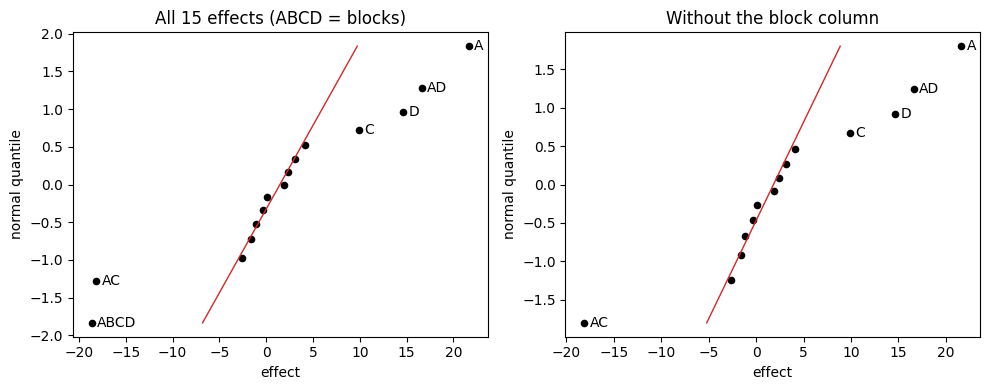

In [25]:
print(rate.groupby("Block")["y"].agg(["sum", "mean"]))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
effect_plot(eff_blk.effect.rename(lambda s: s.replace(":", "")), ax=axes[0], n_label=6, title="All 15 effects (ABCD = blocks)")
effect_plot(eff_blk.effect.drop("A:B:C:D").rename(lambda s: s.replace(":", "")), ax=axes[1],
            title="Without the block column")
plt.tight_layout()
plt.show()

**Python trap.** The formula `y ~ C(Block) + ...` fails with this data frame: the column named `C` hides the patsy function
`C()` that marks a categorical variable. Convert the block to a categorical column instead (or rename the factor column).

In [26]:
rate["Block"] = rate["Block"].astype("category")
m72 = smf.ols("y ~ Block + A*C + A*D", data=rate).fit()
anova_lm(m72).round(4)          # Montgomery, Table 7.7

,df,sum_sq,mean_sq,F,PR(>F)
Block,1.0,1387.5625,1387.5625,66.5808,0.0000
A,1.0,1870.5625,1870.5625,89.7571,0.0000
C,1.0,390.0625,390.0625,18.7168,0.0019
A:C,1.0,1314.0625,1314.0625,63.0540,0.0000
D,1.0,855.5625,855.5625,41.0533,0.0001
A:D,1.0,1105.5625,1105.5625,53.0493,0.0000
Residual,9.0,187.5625,20.8403,NaN,NaN


## 6. Lecture example: why blocking is important (Section 7.5)

Now suppose the design was **not** blocked: the 16 runs were made in random order and the nuisance effect $-20$ affected
the first eight runs. The run order is in Montgomery, Table 7.8.

In [27]:
rate["run_order"] = [8, 11, 1, 3, 9, 12, 2, 13, 7, 6, 16, 5, 14, 15, 10, 4]
rate["y_nb"] = rate.Rate - 20 * (rate.run_order <= 8)
eff_nb = effects_2k(rate, "y_nb", list("ABCD"))
pd.DataFrame({"original": eff_orig.effect, "not blocked": eff_nb.effect}).round(3)

,original,not blocked
term,,
A,21.625,21.625
B,3.125,-1.875
A:B,0.125,-4.875
C,9.875,19.875
A:C,-18.125,-18.125
B:C,2.375,-2.625
A:B:C,1.875,6.875
D,14.625,14.625
A:D,16.625,6.625


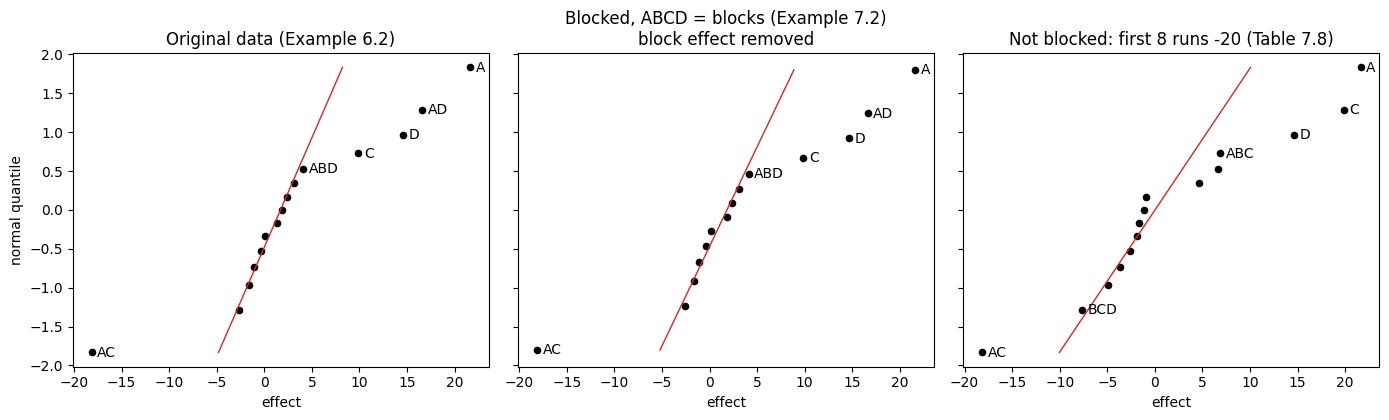

MS_E not blocked (A, C, D, AC): 80.97
MS_E original data (A, C, D, AC, AD): 19.51


In [28]:
# Figure of Lecture 7: normal plots of the effects - original, blocked (Example 7.2), not blocked (Section 7.5)
def short(e):
    return e.rename(lambda s: s.replace(":", ""))

fig, axes = plt.subplots(1, 3, figsize=(14, 4.3), sharey=True)
effect_plot(short(eff_orig.effect), ax=axes[0], n_label=6, title="Original data (Example 6.2)")
effect_plot(short(eff_blk.effect.drop("A:B:C:D")), ax=axes[1], n_label=6,
            title="Blocked, ABCD = blocks (Example 7.2)\nblock effect removed")
effect_plot(short(eff_nb.effect), ax=axes[2], n_label=6, title="Not blocked: first 8 runs -20 (Table 7.8)")
for ax in axes[1:]:
    ax.set_ylabel("")
plt.tight_layout()
plt.show()
m_nb = smf.ols("y_nb ~ A*C + D", data=rate).fit()
print("MS_E not blocked (A, C, D, AC):", round(m_nb.mse_resid, 2))
print("MS_E original data (A, C, D, AC, AD):", round(smf.ols("Rate ~ A*C + A*D", data=rate).fit().mse_resid, 2))

Without blocking, the important interaction $AD$ drops from $16.6$ to $6.6$ and disappears in the noise, $C$ doubles and
$BCD$ appears. The nuisance variability is spread over the effects whose sign columns are correlated with the indicator of the
first eight runs, and part of it inflates the error. **When in doubt, block.**

## 7. Lecture example: partial confounding (Example 7.3)

The plasma etch experiment from Exercise 5 ($A$ gap, $B$ gas flow, $C$ RF power, etch rate), two replicates of the $2^3$
design. Only four runs can be made in one shift: $ABC$ is confounded in replicate I and $AB$ in replicate II.

In [29]:
plasma = pd.read_csv(URL + "plasma.txt", sep="\t")
pc = pd.concat([plasma.assign(Rep=1, y=plasma.R1), plasma.assign(Rep=2, y=plasma.R2)], ignore_index=True)
pc["Blk"] = np.where(pc.Rep == 1, pc.A * pc.B * pc.C, pc.A * pc.B)   # sign of the confounded effect
pc[["Rep", "Blk"]] = pc[["Rep", "Blk"]].astype("category")
pc.groupby(["Rep", "Blk"], observed=True)["y"].sum()

Rep  Blk
1    -1     3016
      1     3068
2    -1     3182
      1     3151
Name: y, dtype: int64

In [30]:
mp = smf.ols("y ~ Rep + Rep:Blk + A*B*C", data=pc).fit()
anova_lm(mp).round(4)          # sequential (type I): blocks first

,df,sum_sq,mean_sq,F,PR(>F)
Rep,1.0,3875.0625,3875.0625,1.5191,0.2726
Rep:Blk,2.0,458.1250,229.0625,0.0898,0.9156
A,1.0,41310.5625,41310.5625,16.1941,0.0101
B,1.0,217.5625,217.5625,0.0853,0.7820
A:B,1.0,3528.0000,3528.0000,1.3830,0.2925
C,1.0,374850.0625,374850.0625,146.9446,0.0001
A:C,1.0,94402.5625,94402.5625,37.0066,0.0017
B:C,1.0,18.0625,18.0625,0.0071,0.9362
A:B:C,1.0,6.1250,6.1250,0.0024,0.9628
Residual,5.0,12754.8125,2550.9625,NaN,NaN


In [31]:
r1, r2 = pc[pc.Rep == 1], pc[pc.Rep == 2]
ss_ab = ((r1.A * r1.B * r1.y).sum()) ** 2 / 8            # AB only from replicate I
ss_abc = ((r2.A * r2.B * r2.C * r2.y).sum()) ** 2 / 8    # ABC only from replicate II
print("SS_AB (rep I) =", ss_ab, "  SS_ABC (rep II) =", ss_abc)

SS_AB (rep I) = 3528.0   SS_ABC (rep II) = 6.125


The sequential ANOVA with the blocks entered first computes $SS_{AB}$ from replicate I and $SS_{ABC}$ from replicate II
automatically; $SS_{\text{Blocks within replicates}} = 458.125$. The important effects are $A$, $C$ and $AC$, as in
Exercise 5. (Montgomery's Table 7.11 has typos in $SS_C$, $SS_{AC}$ and $SS_E$; the values here agree with Chapter 6.)

## Assignment

Work on the assignment in class (in pairs, if you like). Whatever you do not finish in class, finish at home as homework.

* Run the notebook above and make sure you understand each step.
* Solve the following problems from Montgomery, *Design and Analysis of Experiments* (8th edition): **6.33, the center points
  of 6.31, 6.26 with 6.27, 7.7, 7.8 with 7.9 and 7.24**.
* For every test state the hypotheses, the test statistic, its $p$-value and your decision; end each problem with a
  conclusion in one or two sentences.
* The code is only half of the work. Explain every result in your own words: why you chose the model, what the effects
  mean for the process, what the curvature test or the blocking tells you and what your next step would be. Be ready to
  present and defend your solution of any problem at the beginning of the next exercise.
* Submit your solved notebook as a pull request into the `HW/` folder of the course repository, named
  `HW/01NAEX_Ex07_HW_<Surname>.ipynb` (see `HW/README.md`). **Deadline: Sunday 15 November 2026** (there is no lecture
  on 16 November, the next lecture is on 23 November).

### Problem 6.33

Consider the single replicate of the $2^4$ design in Example 6.2 (filtration rate, `Pilot_Plant_Filtration_Rate_Experiment.csv`).
Suppose that we ran five points at the center $(0, 0, 0, 0)$ and observed the responses 93, 95, 91, 89 and 96. Test for
curvature in this experiment. Interpret the results.

**Solution:**

### Problem 6.31 (continued): center points

In Exercise 6 you analyzed the 16 factorial runs of Problem 6.31 (polymer; temperature $A$, catalyst concentration $B$, time
$C$, pressure $D$; responses molecular weight and viscosity). The file `Problem_6_31.txt` also contains **four center points**
(runs 17-20).

In [32]:
p631 = pd.read_csv(URL + "Problem_6_31.txt", sep=";")
p631.tail(6)

,Temperature,Concentration,Time,Pressure,Weight,Viscosity
14,100,8,30,75.0,2500,1500
15,120,8,30,75.0,2710,1600
16,110,6,25,67.5,2515,1500
17,110,6,25,67.5,2500,1460
18,110,6,25,67.5,2400,1525
19,110,6,25,67.5,2475,1500


(a) For both responses estimate the pure error from the center points and test for pure quadratic curvature.

(b) Refit your final models from Exercise 6 with the center points included (coded factors, center points at $0$). Split
the residual into lack of fit and pure error. Is there any lack of fit? Do the conclusions of Problem 6.32 change?

**Solution:**

### Problems 6.26 and 6.27: yield in a semiconductor fabrication plant

An experiment was run in a semiconductor fabrication plant in an effort to increase yield. Five factors, each at two levels,
were studied: $A$ = aperture setting (small, large), $B$ = exposure time (20 % below nominal, 20 % above nominal),
$C$ = development time (30 and 45 s), $D$ = mask dimension (small, large) and $E$ = etch time (14.5 and 15.5 min).
The unreplicated $2^5$ design was run. The file `Ex06_26.csv` contains the 32 runs in standard order (factor levels in
natural units) followed by the four additional runs of Problem 6.27.

In [33]:
p626 = pd.read_csv(URL + "Ex06_26.csv", sep=";")
p626

,Aperture,ExposureTime,DevelopTime,MaskDimension,EtchTime,Yield
0,small,-20,30.0,Small,14.5,7
1,large,-20,30.0,Small,14.5,9
2,small,20,30.0,Small,14.5,34
3,large,20,30.0,Small,14.5,55
4,small,-20,45.0,Small,14.5,16
5,large,-20,45.0,Small,14.5,20
6,small,20,45.0,Small,14.5,40
7,large,20,45.0,Small,14.5,60
8,small,-20,30.0,Large,14.5,8
9,large,-20,30.0,Large,14.5,10


**Problem 6.26** (use the first 32 runs; code the factors to $-1$/$+1$ first)

(a) Construct a normal probability plot of the effect estimates. Which effects appear to be large?

(b) Conduct an analysis of variance to confirm your findings for part (a).

(c) Write down the regression model relating yield to the significant process variables.

(d) Plot the residuals on normal probability paper. Is the plot satisfactory?

(e) Plot the residuals versus the predicted yields and versus each of the five factors. Comment on the plots.

(f) Interpret any significant interactions.

(g) What are your recommendations regarding process operating conditions?

(h) Project the $2^5$ design in this problem into a $2^k$ design in the important factors. Sketch the design and show the
average and range of yields at each run. Does this sketch aid in interpreting the results of this experiment?

**Solution:**

**Problem 6.27.** Suppose that the experimenter had run four center points in addition to the 32 trials in the original
experiment. The yields obtained at the center point runs were 68, 74, 76 and 70 (the last four rows of the file).

(a) Reanalyze the experiment, including a test for pure quadratic curvature.

(b) Discuss what your next step would be.

Note: aperture ($A$) and mask dimension ($D$) are qualitative factors. Look at how the four runs are recorded in the file:
each of them has a different combination of $A$ and $D$. Discuss whether their variance can be used as pure error, and
discuss what a "center point" means in this case (Montgomery, Section 6.8, remark 5).

**Solution:**

### Problem 7.7

Using the data from the $2^5$ design in Problem 6.26, construct and analyze a design in two blocks with $ABCDE$ confounded
with blocks.

**Solution:**

### Problems 7.8 and 7.9

**7.8.** Repeat Problem 7.7 assuming that four blocks are necessary. Suggest a reasonable confounding scheme.

**7.9.** Suppose that it was necessary to run the design of Problem 6.26 in four blocks with $ACDE$ and $BCD$ (and
consequently $ABE$) confounded. Analyze the data from this design.

Hint: `confounded_effects()` and `design_in_blocks()` from the setup cell.

**Solution:**

### Problem 7.24: partial confounding

Problem 6.1: an engineer is interested in the effects of cutting speed ($A$), tool geometry ($B$) and cutting angle ($C$) on the
life (in hours) of a machine tool. Three replicates of the $2^3$ design were run. The file `Problem_6_1.txt` lists the three
replicates (I, II, III) of each treatment combination one after another.

In [34]:
p61 = pd.read_csv(URL + "Problem_6_1.txt", sep=";")
p61.head(6)

,CuttingSpeed,ToolGeometry,CuttingAngle,LifeHours
0,-1,-1,-1,22
1,-1,-1,-1,31
2,-1,-1,-1,25
3,1,-1,-1,32
4,1,-1,-1,43
5,1,-1,-1,29


Suppose that in Problem 6.1 we had confounded $ABC$ in replicate I, $AB$ in replicate II and $BC$ in replicate III (each
replicate run in two blocks of four runs). Calculate the factor effect estimates. Construct the analysis of variance table.
Compare the results with the analysis of the unconfounded design (each replicate a block).

**Solution:**